# Data Exploration 

In [112]:

from pathlib import Path
from pandas.plotting import scatter_matrix
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
DATA_DIR = Path.cwd() / "Data"
print(f"Using data directory: {DATA_DIR}")
import statistics as st


Using data directory: c:\Users\dinil\OneDrive\Documents\GitHub\Fulfillment-Pulsa\Data


In [113]:
temperature = pd.read_csv(DATA_DIR / "Temperature_Data.csv")
rainfall = pd.read_csv(DATA_DIR / "rainfall_Data.csv")

print("rainfall shape:", rainfall.shape)
print("rainfall shape:", rainfall.shape)
print("rainfall columns:", list(rainfall.columns))
print("rainfall columns:", list(rainfall.columns))


rainfall shape: (254, 8)
rainfall shape: (254, 8)
rainfall columns: ['Product code', 'Bureau of Meteorology station number', 'Year', 'Month', 'Day', 'Rainfall amount (millimetres)', 'Period over which rainfall was measured (days)', 'Quality']
rainfall columns: ['Product code', 'Bureau of Meteorology station number', 'Year', 'Month', 'Day', 'Rainfall amount (millimetres)', 'Period over which rainfall was measured (days)', 'Quality']


In [114]:
temperature.head()

,Product code,Bureau of Meteorology station number,Year,Month,Day,Maximum temperature (Degree C),Days of accumulation of maximum temperature,Quality
0,IDCJAC0010,86338,2013,1,1,NaN,NaN,NaN
1,IDCJAC0010,86338,2013,1,2,NaN,NaN,NaN
2,IDCJAC0010,86338,2013,1,3,NaN,NaN,NaN
3,IDCJAC0010,86338,2013,1,4,NaN,NaN,NaN
4,IDCJAC0010,86338,2013,1,5,NaN,NaN,NaN


# Temperature dataset exploration

In [115]:
print(temperature.isnull().sum())
print(temperature.isna().sum)

Product code                                     0
Bureau of Meteorology station number             0
Year                                             0
Month                                            0
Day                                              0
Maximum temperature (Degree C)                 155
Days of accumulation of maximum temperature    155
Quality                                        156
dtype: int64
<bound method DataFrame.sum of       Product code  Bureau of Meteorology station number   Year  Month    Day  \
0            False                                 False  False  False  False   
1            False                                 False  False  False  False   
2            False                                 False  False  False  False   
3            False                                 False  False  False  False   
4            False                                 False  False  False  False   
...            ...                                   ...    ..

In [116]:
print(temperature.dropna(inplace = True))
print(temperature.isnull().sum())

None
Product code                                   0
Bureau of Meteorology station number           0
Year                                           0
Month                                          0
Day                                            0
Maximum temperature (Degree C)                 0
Days of accumulation of maximum temperature    0
Quality                                        0
dtype: int64


In [117]:
temperature.describe()

,Bureau of Meteorology station number,Year,Month,Day,Maximum temperature (Degree C),Days of accumulation of maximum temperature
count,4845.0,4845.000000,4845.000000,4845.000000,4845.000000,4845.0
mean,86338.0,2019.548607,6.540970,15.709598,20.350857,1.0
std,0.0,3.851116,3.416188,8.802803,6.021581,0.0
min,86338.0,2013.000000,1.000000,1.000000,9.000000,1.0
25%,86338.0,2016.000000,4.000000,8.000000,15.800000,1.0
50%,86338.0,2020.000000,7.000000,16.000000,19.100000,1.0
75%,86338.0,2023.000000,9.000000,23.000000,23.600000,1.0
max,86338.0,2026.000000,12.000000,31.000000,43.500000,1.0


In [118]:
temperature["date"] = pd.to_datetime(temperature[["Year", "Month", "Day"]])


In [119]:
temperature.duplicated().sum()

np.int64(0)

In [120]:
temp_column = "Maximum temperature (Degree C)"

temperature.loc[
    temperature[temp_column].idxmax(),
    ["date", temp_column]
]

date                              2019-12-20 00:00:00
Maximum temperature (Degree C)                   43.5
Name: 2544, dtype: object

In [121]:
temp_column = "Maximum temperature (Degree C)"

temperature.loc[
    temperature[temp_column].idxmin(),
    ["date", temp_column]
]

date                              2017-08-03 00:00:00
Maximum temperature (Degree C)                    9.0
Name: 1675, dtype: object

In [122]:
temp_column = "Maximum temperature (Degree C)"
condition_one = temperature[temp_column] > 30
condition_two = temperature["date"].dt.year >= 2020

temperature.loc[condition_one & condition_two, ["date", temp_column]]

,date,Maximum temperature (Degree C)
2558,2020-01-03,36.6
2564,2020-01-09,31.9
2565,2020-01-10,32.9
2568,2020-01-13,32.2
2569,2020-01-14,33.8
...,...,...
4798,2026-02-20,30.8
4805,2026-02-27,31.0
4806,2026-02-28,30.5
4807,2026-03-01,30.7


In [123]:
hot_days = temperature[
    temperature["Maximum temperature (Degree C)"] > 30
].copy()

hot_days

,Product code,Bureau of Meteorology station number,Year,Month,Day,Maximum temperature (Degree C),Days of accumulation of maximum temperature,Quality,date
292,IDCJAC0010,86338,2013,10,20,31.6,1.0,Y,2013-10-20
309,IDCJAC0010,86338,2013,11,6,30.3,1.0,Y,2013-11-06
322,IDCJAC0010,86338,2013,11,19,30.6,1.0,Y,2013-11-19
330,IDCJAC0010,86338,2013,11,27,32.7,1.0,Y,2013-11-27
334,IDCJAC0010,86338,2013,12,1,30.8,1.0,Y,2013-12-01
...,...,...,...,...,...,...,...,...,...
4798,IDCJAC0010,86338,2026,2,20,30.8,1.0,N,2026-02-20
4805,IDCJAC0010,86338,2026,2,27,31.0,1.0,N,2026-02-27
4806,IDCJAC0010,86338,2026,2,28,30.5,1.0,N,2026-02-28
4807,IDCJAC0010,86338,2026,3,1,30.7,1.0,N,2026-03-01


In [124]:
condition_one = temperature["Maximum temperature (Degree C)"] > 30
condition_two = temperature["date"].dt.year >= 2020

temperature[(condition_one) & (condition_two)]


,Product code,Bureau of Meteorology station number,Year,Month,Day,Maximum temperature (Degree C),Days of accumulation of maximum temperature,Quality,date
2558,IDCJAC0010,86338,2020,1,3,36.6,1.0,Y,2020-01-03
2564,IDCJAC0010,86338,2020,1,9,31.9,1.0,Y,2020-01-09
2565,IDCJAC0010,86338,2020,1,10,32.9,1.0,Y,2020-01-10
2568,IDCJAC0010,86338,2020,1,13,32.2,1.0,Y,2020-01-13
2569,IDCJAC0010,86338,2020,1,14,33.8,1.0,Y,2020-01-14
...,...,...,...,...,...,...,...,...,...
4798,IDCJAC0010,86338,2026,2,20,30.8,1.0,N,2026-02-20
4805,IDCJAC0010,86338,2026,2,27,31.0,1.0,N,2026-02-27
4806,IDCJAC0010,86338,2026,2,28,30.5,1.0,N,2026-02-28
4807,IDCJAC0010,86338,2026,3,1,30.7,1.0,N,2026-03-01


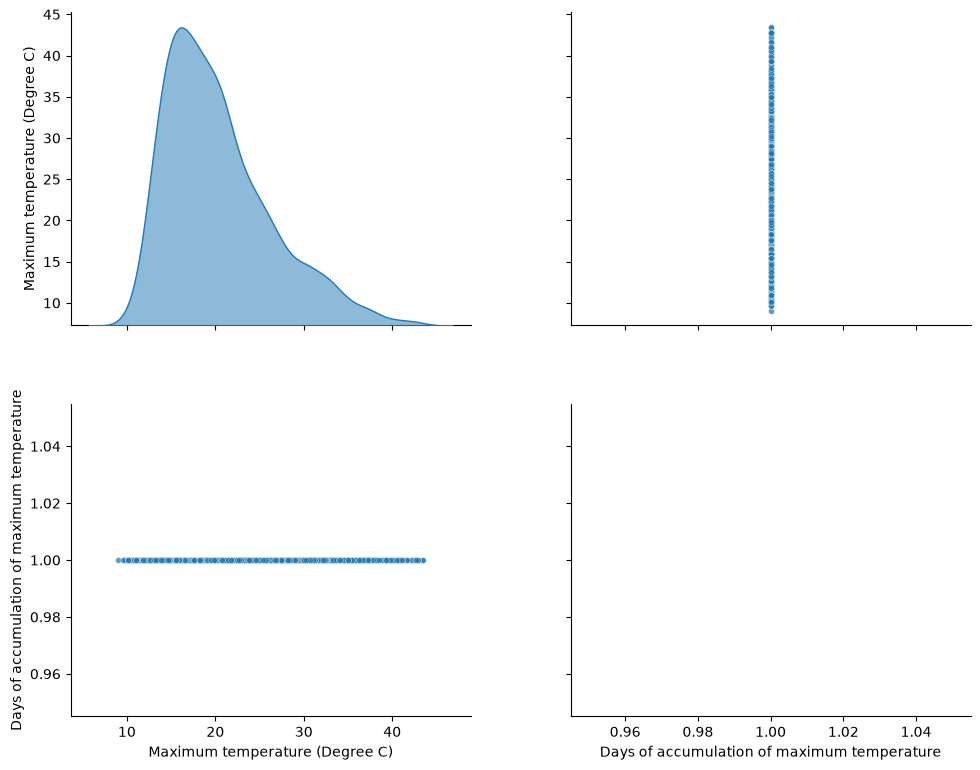

In [125]:
temp_vars = [
    "Maximum temperature (Degree C)",
    "Days of accumulation of maximum temperature",
]

pairplot_df = temperature[temp_vars].dropna()

g = sns.pairplot(
    pairplot_df,
    diag_kind="kde",
    height=2.4,
    aspect=1.1,
    plot_kws={"s": 18, "alpha": 0.7},
    diag_kws={"fill": True, "alpha": 0.5},
)

g.fig.set_size_inches(10, 8)
g.fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.96,
    wspace=0.25,
    hspace=0.25,
)

plt.show()


(array([ 152., 1081., 1266.,  965.,  593.,  344.,  244.,  123.,   55.,
          22.]),
 array([ 9.  , 12.45, 15.9 , 19.35, 22.8 , 26.25, 29.7 , 33.15, 36.6 ,
        40.05, 43.5 ]),
 <BarContainer object of 10 artists>)

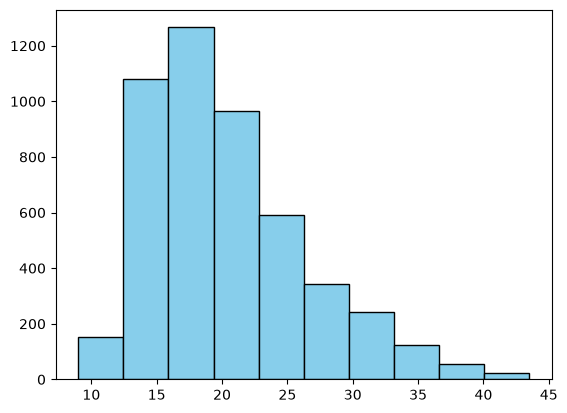

In [126]:
plt.hist(temperature["Maximum temperature (Degree C)"], bins=10, color='skyblue', edgecolor='black')

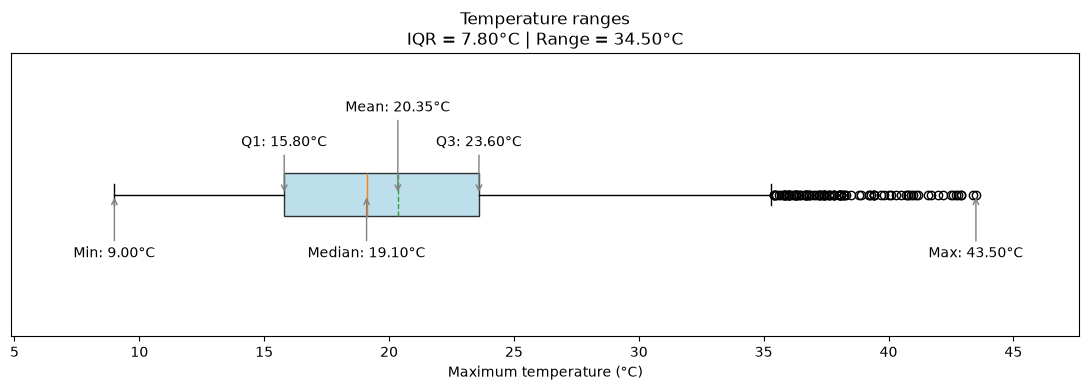

In [127]:
temps = temperature["Maximum temperature (Degree C)"].dropna()

minimum = temps.min()
maximum = temps.max()
median = temps.median()
mean = temps.mean()
q1 = temps.quantile(0.25)
q3 = temps.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))

ax.boxplot(
    temps,
    showmeans=True,
    orientation="horizontal",
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

labels = [
    ("Min", minimum, -45),
    ("Q1", q1, 35),
    ("Median", median, -45),
    ("Mean", mean, 60),
    ("Q3", q3, 35),
    ("Max", maximum, -45),
]

for label, value, offset in labels:
    ax.annotate(
        f"{label}: {value:.2f}°C",
        xy=(value, 1),
        xytext=(0, offset),
        textcoords="offset points",
        ha="center",
        arrowprops=dict(arrowstyle="->", color="gray")
    )

ax.set_title(
    f"Temperature ranges\n"
    f"IQR = {IQR:.2f}°C | Range = {maximum - minimum:.2f}°C"
)
ax.set_xlabel("Maximum temperature (°C)")
ax.set_yticks([])
ax.margins(x=0.12)

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

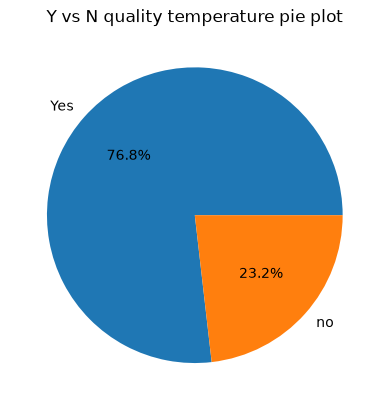

In [128]:
# 1. Set the date column as the index
# temperature['date'] = pd.to_datetime(temperature['date'])
# temperature['date'].set_index('date', inplace=True)

# 2. Resample to monthly and apply an aggregation (e.g., mean, sum)
# monthly_df = df.resample('ME').sum()

quality_count = temperature["Quality"].value_counts()
quality_count
fig, ax = plt.subplots()
label = ["Yes", "no"]
ax.pie(quality_count, labels = label, autopct= "%1.1f%%")
plt.title("Y vs N quality temperature pie plot")
plt.show

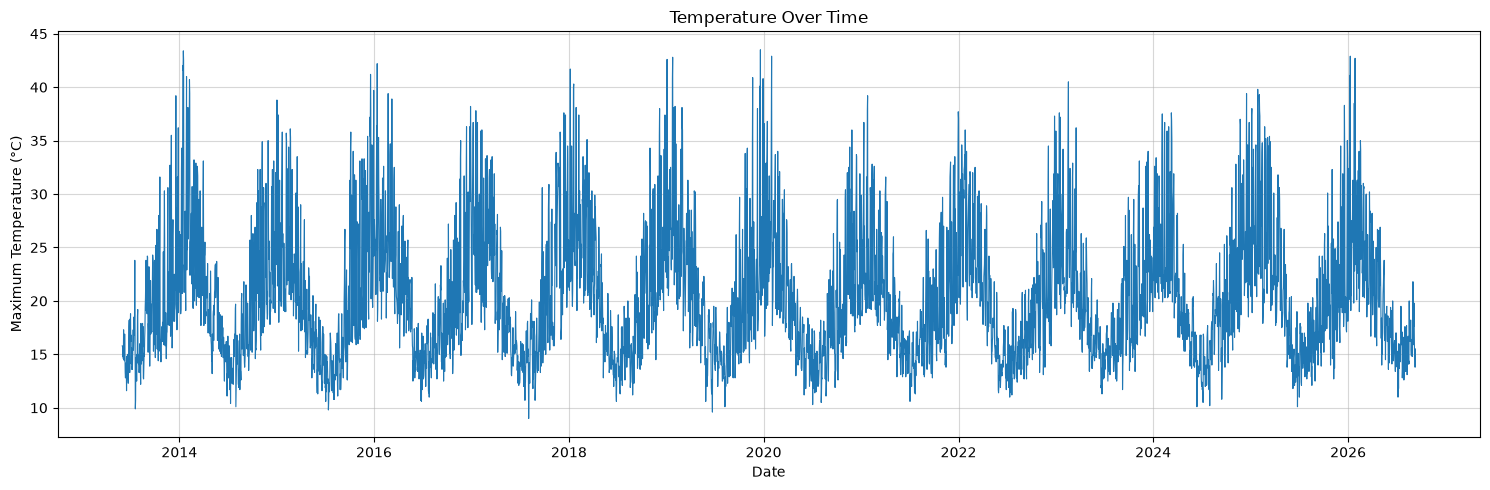

In [129]:
import matplotlib.pyplot as plt

# Time series plot for maximum temperature

temperature = temperature.copy()
temperature["date"] = pd.to_datetime(temperature["date"])
temperature = temperature.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    temperature["date"],
    temperature["Maximum temperature (Degree C)"],
    linewidth=0.8,
    color="tab:blue",
)
ax.set_xlabel("Date")
ax.set_ylabel("Maximum Temperature (°C)")
ax.set_title("Temperature Over Time")
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()

In [130]:
temperature.info()

<class 'pandas.DataFrame'>
RangeIndex: 4845 entries, 0 to 4844
Data columns (total 9 columns):
 #   Column                                       Non-Null Count  Dtype         
---  ------                                       --------------  -----         
 0   Product code                                 4845 non-null   str           
 1   Bureau of Meteorology station number         4845 non-null   int64         
 2   Year                                         4845 non-null   int64         
 3   Month                                        4845 non-null   int64         
 4   Day                                          4845 non-null   int64         
 5   Maximum temperature (Degree C)               4845 non-null   float64       
 6   Days of accumulation of maximum temperature  4845 non-null   float64       
 7   Quality                                      4845 non-null   str           
 8   date                                         4845 non-null   datetime64[us]
dtypes: dateti

# Rainfall data exploration

In [131]:
rainfall.isnull().sum()

Product code                                        0
Bureau of Meteorology station number                0
Year                                                0
Month                                               0
Day                                                 0
Rainfall amount (millimetres)                       0
Period over which rainfall was measured (days)    152
Quality                                             0
dtype: int64

In [132]:
rainfall.describe()

,Bureau of Meteorology station number,Year,Month,Day,Rainfall amount (millimetres),Period over which rainfall was measured (days)
count,254.0,254.0,254.000000,254.000000,254.000000,102.0
mean,86232.0,2026.0,4.720472,15.283465,1.461811,1.0
std,0.0,0.0,2.427733,8.864280,3.536137,0.0
min,86232.0,2026.0,1.000000,1.000000,0.000000,1.0
25%,86232.0,2026.0,3.000000,8.000000,0.000000,1.0
50%,86232.0,2026.0,5.000000,15.000000,0.000000,1.0
75%,86232.0,2026.0,7.000000,23.000000,1.000000,1.0
max,86232.0,2026.0,9.000000,31.000000,25.000000,1.0


In [133]:
rainfall["date"] = pd.to_datetime(rainfall[["Year", "Month", "Day"]])

In [134]:
rainfall.duplicated().sum()

np.int64(0)

In [135]:
rain_column = "Rainfall amount (millimetres)"

rainfall.loc[
    rainfall[rain_column].idxmax(),
    ["date", rain_column]
]

date                             2026-08-10 00:00:00
Rainfall amount (millimetres)                   25.0
Name: 221, dtype: object

In [136]:
rain_column = "Rainfall amount (millimetres)"

rainfall.loc[
    rainfall[rain_column].idxmin(),
    ["date", rain_column]
]

date                             2026-01-01 00:00:00
Rainfall amount (millimetres)                    0.0
Name: 0, dtype: object

In [137]:
rainy_days = rainfall[
    rainfall["Rainfall amount (millimetres)"] > 0
].copy()

rainy_days

,Product code,Bureau of Meteorology station number,Year,Month,Day,Rainfall amount (millimetres),Period over which rainfall was measured (days),Quality,date
9,IDCJAC0009,86232,2026,1,10,0.3,1.0,Y,2026-01-10
21,IDCJAC0009,86232,2026,1,22,0.6,1.0,Y,2026-01-22
31,IDCJAC0009,86232,2026,2,1,1.7,1.0,N,2026-02-01
39,IDCJAC0009,86232,2026,2,9,1.4,1.0,N,2026-02-09
42,IDCJAC0009,86232,2026,2,12,11.2,1.0,N,2026-02-12
...,...,...,...,...,...,...,...,...,...
240,IDCJAC0009,86232,2026,8,29,1.7,1.0,N,2026-08-29
246,IDCJAC0009,86232,2026,9,4,2.8,1.0,N,2026-09-04
247,IDCJAC0009,86232,2026,9,5,7.6,1.0,N,2026-09-05
248,IDCJAC0009,86232,2026,9,6,0.8,1.0,N,2026-09-06


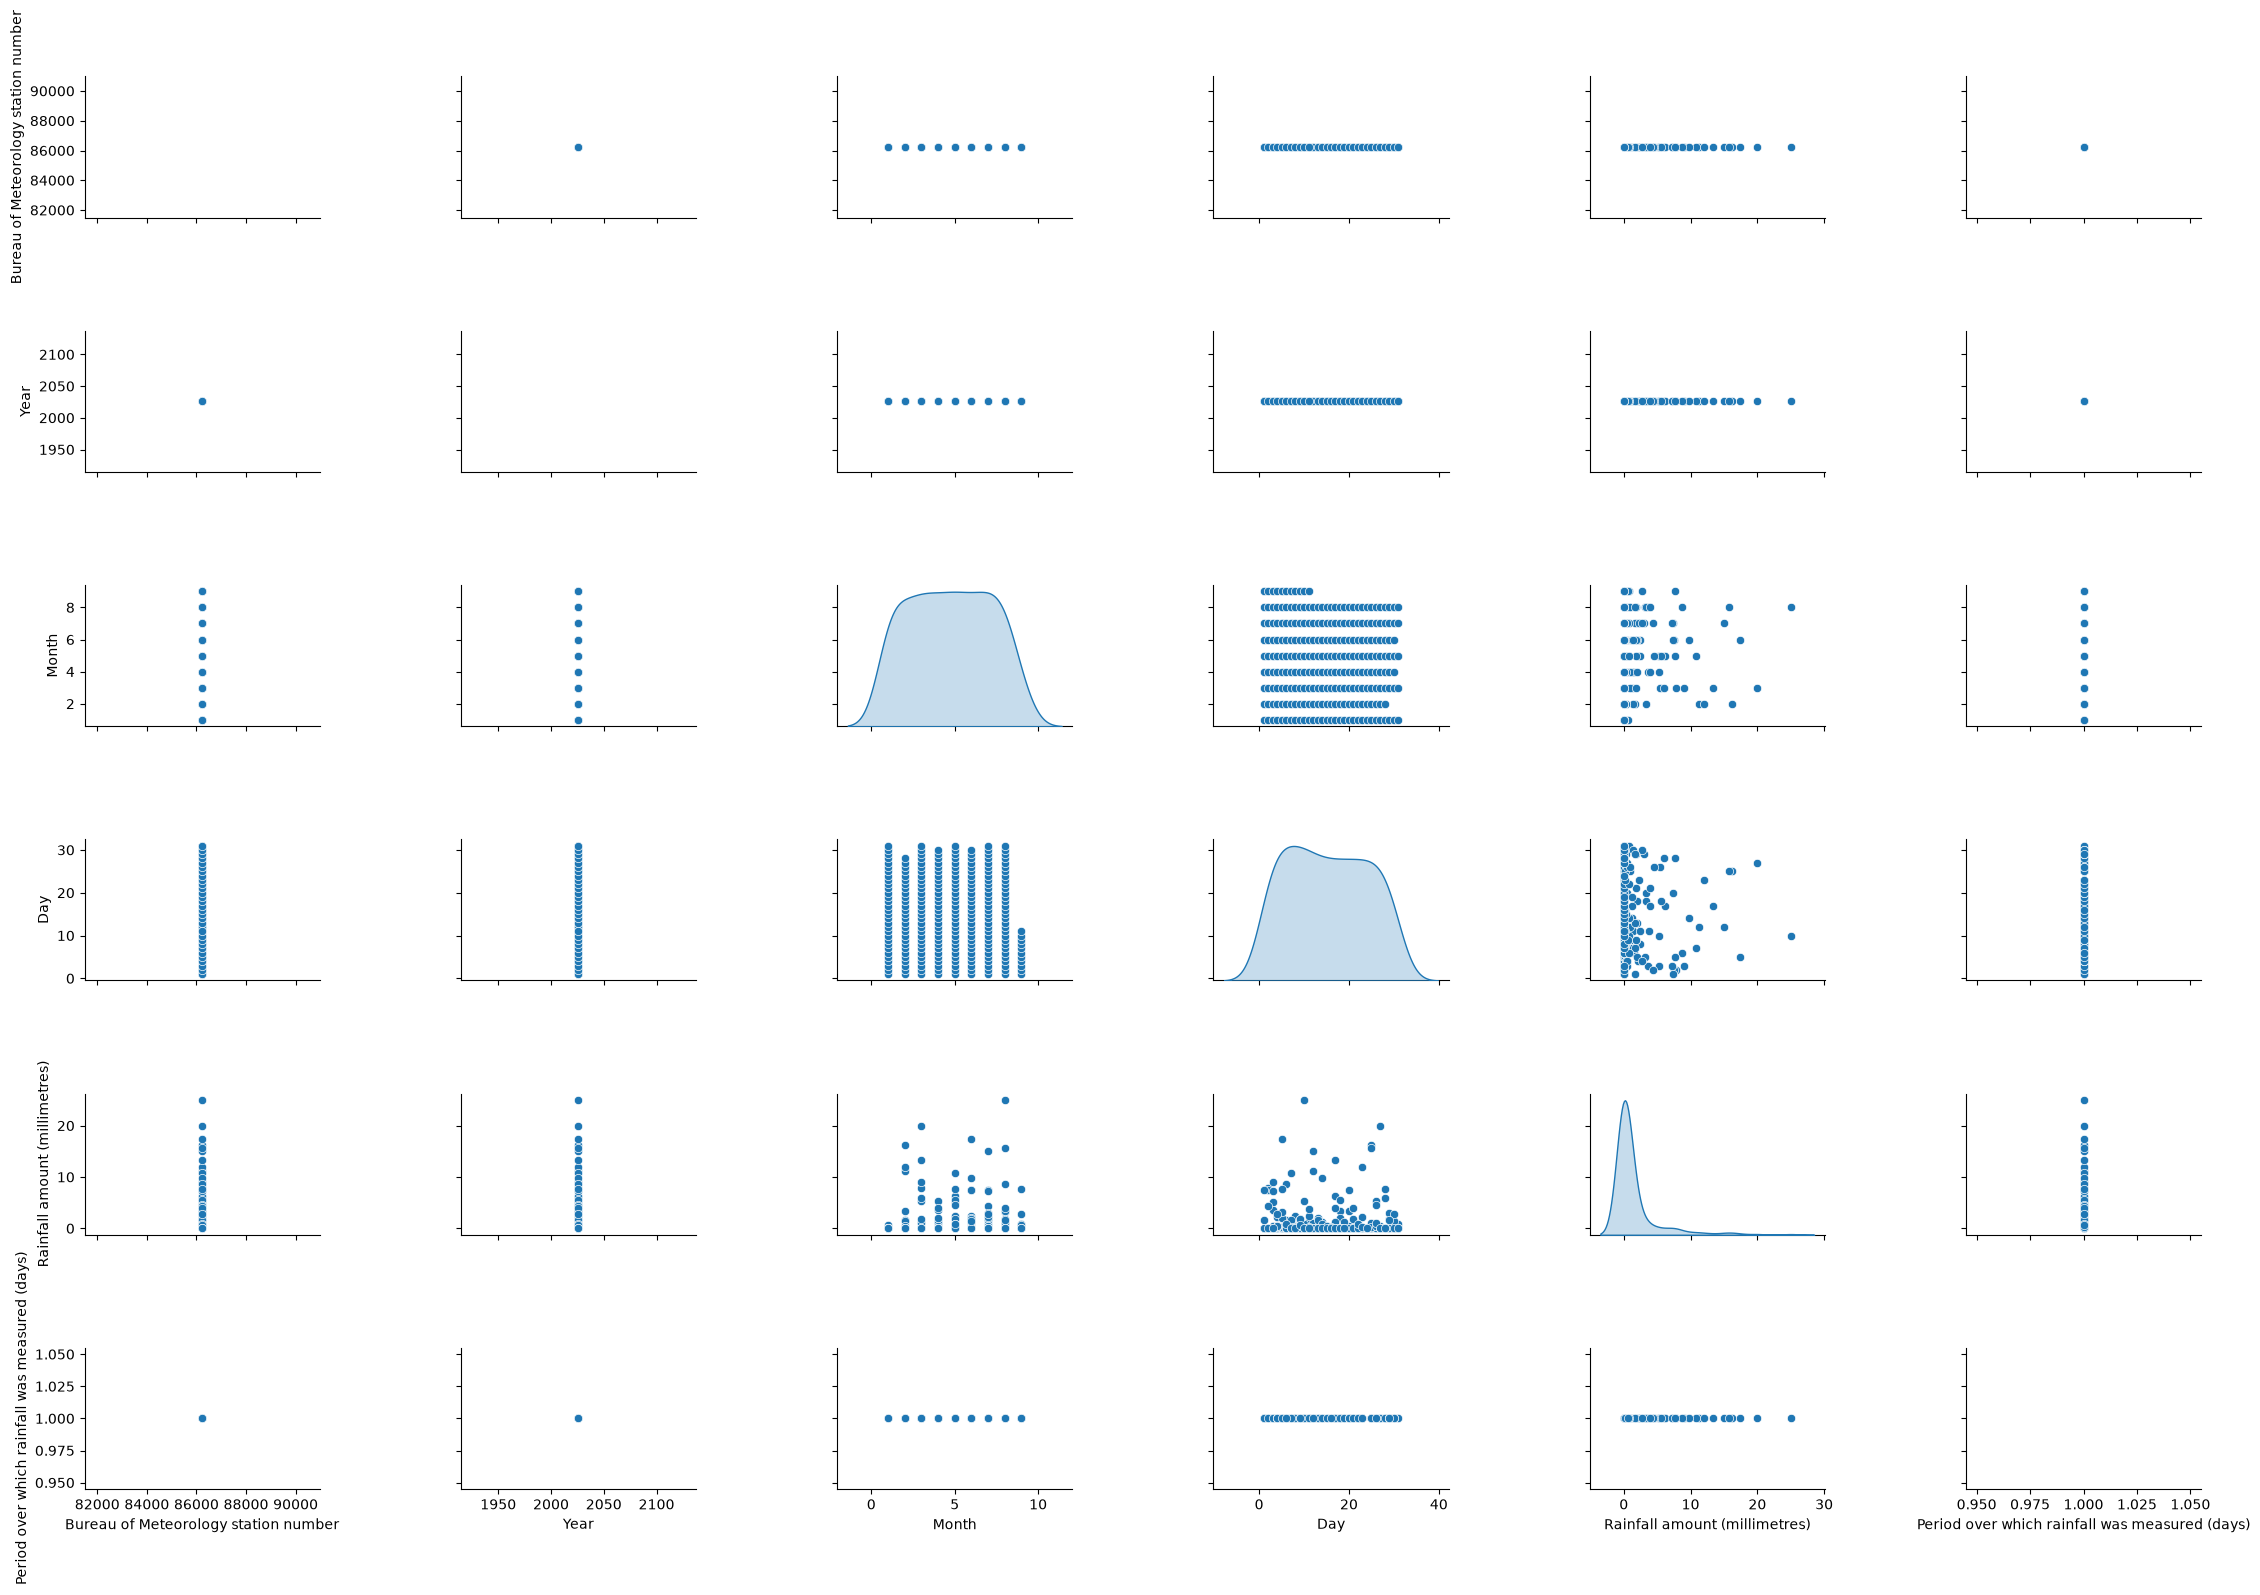

In [138]:
# 2. Generate the pairplot
# 'hue' color-codes the data points based on a categorical column
plot = sns.pairplot(rainfall,  diag_kind='kde', height=2.5, aspect=1.5)
plot.figure.subplots_adjust(wspace=0.6, hspace=0.8)


C:\Users\dinil\AppData\Local\Temp\ipykernel_34368\771989217.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


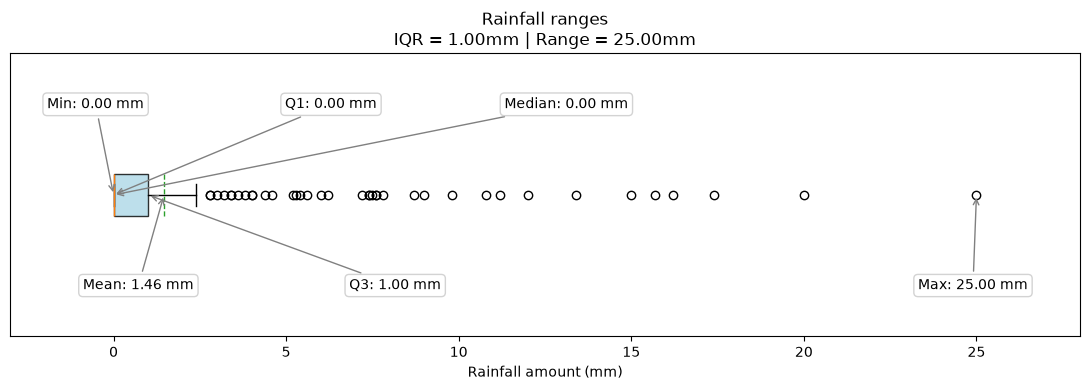

In [139]:
rain = rainfall["Rainfall amount (millimetres)"].dropna()

minimum = rain.min()
maximum = rain.max()
median = rain.median()
mean = rain.mean()
q1 = rain.quantile(0.25)
q3 = rain.quantile(0.75)
IQR = q3 - q1

fig, ax = plt.subplots(figsize=(11, 4))

ax.boxplot(
    rain,
    showmeans=True,
    vert=False,
    meanline=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", alpha=0.8),
)

# Space labels across the axes even when several statistics are near zero.
labels = [
    ("Min", minimum, (0.08, 0.82)),
    ("Q1", q1, (0.30, 0.82)),
    ("Median", median, (0.52, 0.82)),
    ("Mean", mean, (0.12, 0.18)),
    ("Q3", q3, (0.36, 0.18)),
    ("Max", maximum, (0.90, 0.18)),
]

for label, value, position in labels:
    ax.annotate(
        f"{label}: {value:.2f} mm",
        xy=(value, 1),
        xytext=position,
        textcoords="axes fraction",
        ha="center",
        va="center",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="lightgray"),
        arrowprops=dict(arrowstyle="->", color="gray"),
    )

ax.set_title(
    f"Rainfall ranges\n"
    f"IQR = {IQR:.2f}mm | Range = {maximum - minimum:.2f}mm"
)
ax.set_xlabel("Rainfall amount (mm)")
ax.set_yticks([])
ax.margins(x=0.12)

plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

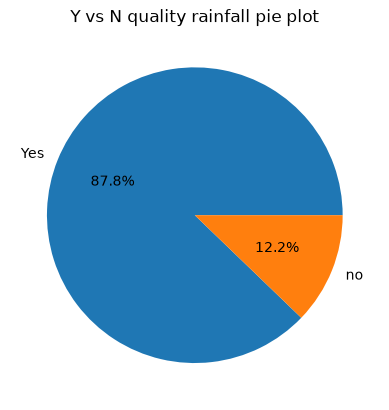

In [140]:
# 1. Set the date column as the index
# temperature['date'] = pd.to_datetime(temperature['date'])
# temperature['date'].set_index('date', inplace=True)

# 2. Resample to monthly and apply an aggregation (e.g., mean, sum)
# monthly_df = df.resample('ME').sum()

quality_count = rainfall["Quality"].value_counts()
quality_count
fig, ax = plt.subplots()
label = ["Yes", "no"]
ax.pie(quality_count, labels = label, autopct= "%1.1f%%")
plt.title("Y vs N quality rainfall pie plot")
plt.show

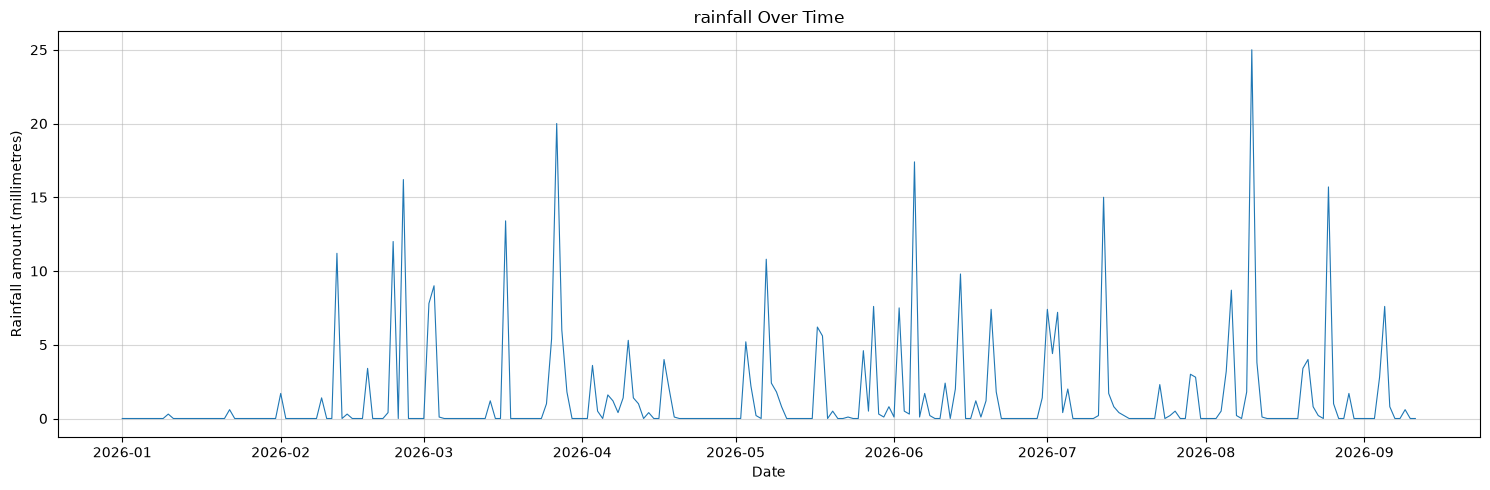

In [141]:
import matplotlib.pyplot as plt

# Time series plot for maximum temperature

rainfall = rainfall.copy()
rainfall["date"] = pd.to_datetime(rainfall["date"])
rainfall = rainfall.sort_values("date").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    rainfall["date"],
    rainfall["Rainfall amount (millimetres)"],
    linewidth=0.8,
    color="tab:blue",
)
ax.set_xlabel("Date")
ax.set_ylabel("Rainfall amount (millimetres)")
ax.set_title("rainfall Over Time")
ax.grid(True, alpha=0.5)
plt.tight_layout()
plt.show()